In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

In [8]:
df = pd.read_csv("/Users/nlvssurya/Desktop/rainfall/rainfall-prediction-classifier/weatherAUS copy.csv")

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Loaded Successfully
Dataset Shape: (145460, 23)

First Five Records:
         Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Press

In [9]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df.dropna(subset=["Date", "RainTomorrow"], inplace=True)

df["RainTomorrow"] = df["RainTomorrow"].astype(str).str.strip()

df = df[df["RainTomorrow"].isin(["Yes", "No"])].copy()

# Convert target into numerical values
df["RainTomorrow"] = df["RainTomorrow"].map({
    "No": 0,
    "Yes": 1
})

In [10]:
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Year"] = df["Date"].dt.year

df.drop(columns=["Date"], inplace=True)


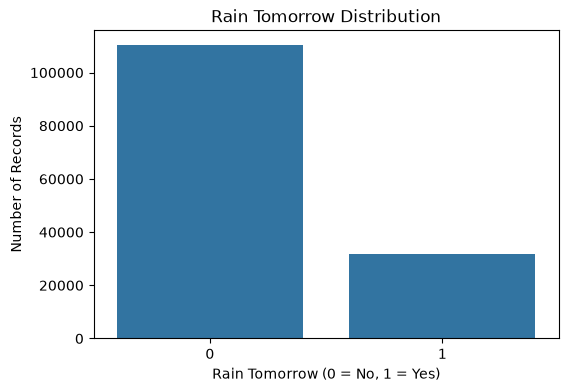

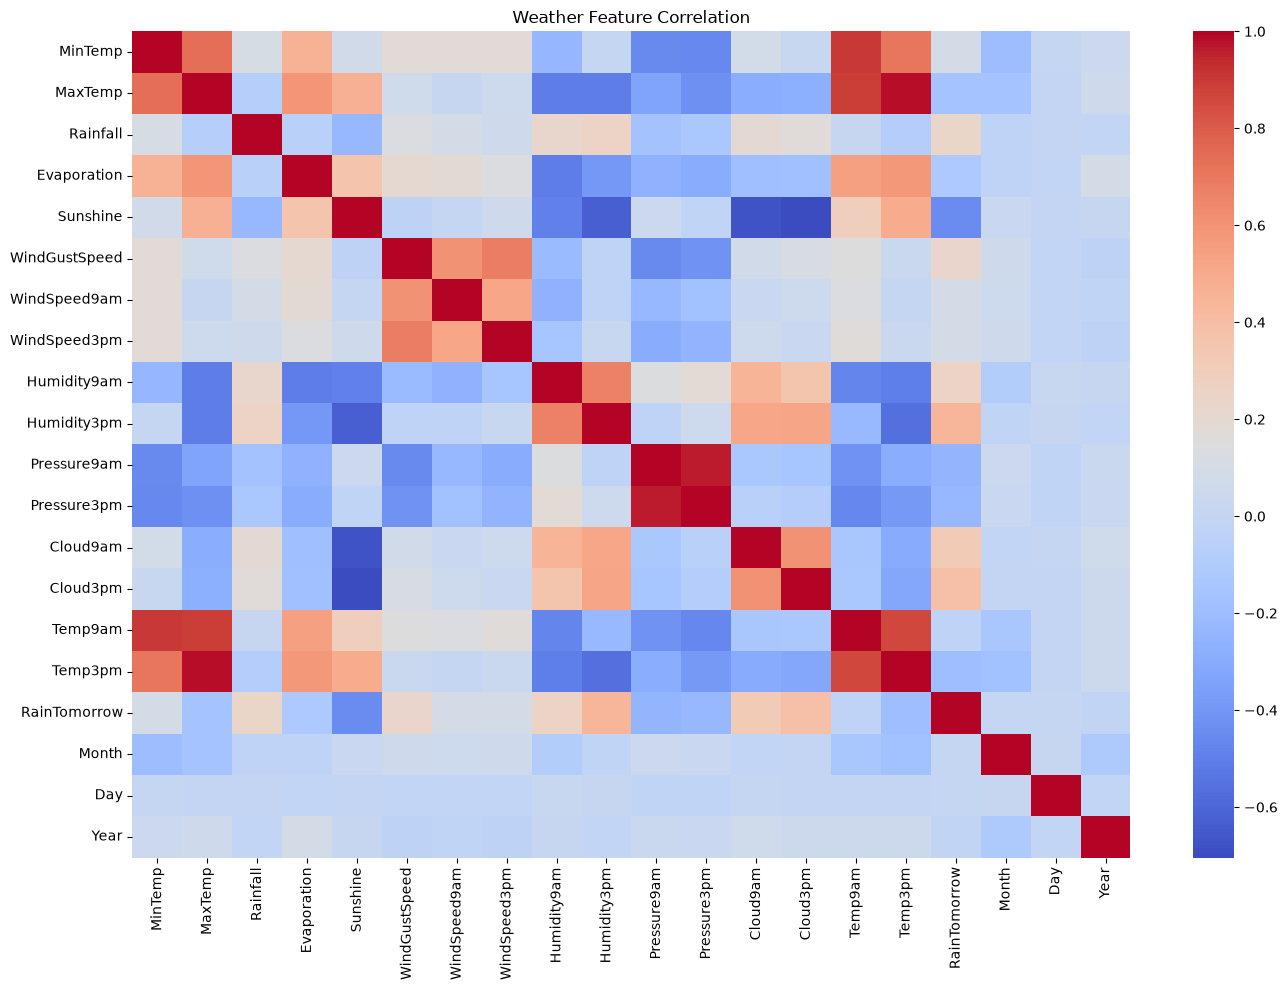

In [11]:
os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="RainTomorrow"
)

plt.title("Rain Tomorrow Distribution")
plt.xlabel("Rain Tomorrow (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.savefig("outputs/rainfall_distribution.png")
plt.show()

# Correlation heatmap for numerical features
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Weather Feature Correlation")

plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png")
plt.show()

In [12]:
X = df.drop(columns=["RainTomorrow"])
y = df["RainTomorrow"]

# Chronological split: keep observations from
# the same date together.
unique_dates = pd.to_datetime(
    pd.read_csv("weatherAUS copy.csv")["Date"],
    errors="coerce"
).dropna().sort_values().drop_duplicates()

split_date = unique_dates.iloc[int(len(unique_dates) * 0.80)]

original_dates = pd.to_datetime(
    pd.read_csv("weatherAUS copy.csv")["Date"],
    errors="coerce"
)

# Use the cleaned dataframe's original row indices
train_indices = df.index[original_dates.loc[df.index] < split_date]
test_indices = df.index[original_dates.loc[df.index] >= split_date]

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


Training Records: 109302
Testing Records: 32891


In [13]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [14]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=18,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}

In [15]:
results = []
trained_models = {}

for name, classifier in models.items():

    print("\nTraining:", name)

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test, probabilities
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc
    })

    trained_models[name] = model

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["No Rain", "Rain"],
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Rain", "Rain"],
        yticklabels=["No Rain", "Rain"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()

    plt.savefig(
        "outputs/" + name.replace(" ", "_") + "_matrix.png"
    )

    plt.close()



Training: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.92      0.81      0.86     25680
        Rain       0.52      0.73      0.61      7211

    accuracy                           0.79     32891
   macro avg       0.72      0.77      0.74     32891
weighted avg       0.83      0.79      0.81     32891


Training: Decision Tree

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.90      0.78      0.83     25680
        Rain       0.46      0.68      0.55      7211

    accuracy                           0.76     32891
   macro avg       0.68      0.73      0.69     32891
weighted avg       0.80      0.76      0.77     32891


Training: Random Forest

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.88      0.93      0.91     25680
        Rain       0.70      0.54      0.61      7211

    accuracy                 

In [17]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
)

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)


MODEL COMPARISON
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC
        Extra Trees  0.842388   0.651382 0.604770  0.627211 0.871150
      Random Forest  0.848378   0.698784 0.542088  0.610543 0.869821
Logistic Regression  0.794716   0.522644 0.734572  0.610746 0.858622
      Decision Tree  0.755131   0.460217 0.676189  0.547681 0.776444


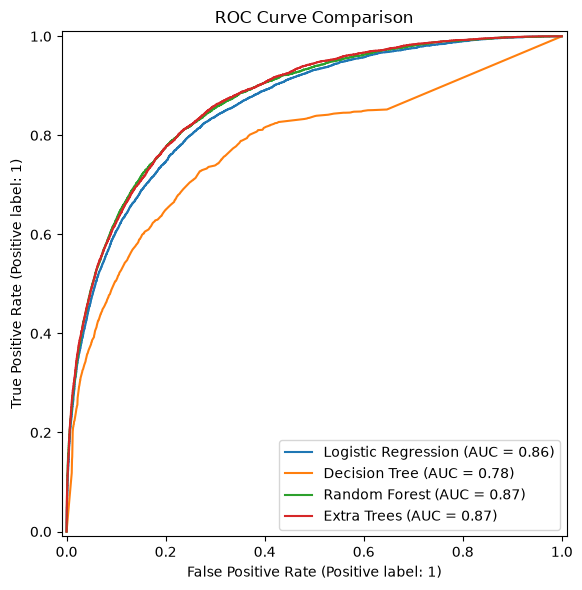

In [18]:
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.title("ROC Curve Comparison")

plt.tight_layout()

plt.savefig("outputs/roc_comparison.png")

plt.show()

In [19]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

joblib.dump(
    best_model,
    "outputs/best_rainfall_model.pkl"
)

print("\nBest Model:", best_model_name)

print("Best Model ROC AUC:",
      results_df.iloc[0]["ROC AUC"])

print("\nBest model saved successfully!")


Best Model: Extra Trees
Best Model ROC AUC: 0.8711504220144803

Best model saved successfully!


In [20]:
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)[0]

probability = best_model.predict_proba(sample)[0][1]

print("\nSAMPLE RAINFALL PREDICTION")

if prediction == 1:
    print("Prediction: Rain Tomorrow")
else:
    print("Prediction: No Rain Tomorrow")

print("Rain Probability:", round(probability * 100, 2), "%")



SAMPLE RAINFALL PREDICTION
Prediction: No Rain Tomorrow
Rain Probability: 17.86 %
